# Train the rocket controller offline

The idea here is to train the model based on the expert data. You can use all the data or not. There may be some benefit from not using all of the data.

Use this file as both training and data analysis to make your informed changes.

I expect extra plots/records of runs; If you submit this file unchanged you will only be able to receive a maximum score of 1 out of 2.


In [1]:
# DO NOT REMOVE THESE
# These two lines make sure any changes you make in scaffold.py
# are automatically reloaded each time you run a cell in this notebook.
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scaffold import Controller
import numpy as np

landings_path = "landings.csv"
weights_path = "weights.npz"

# You will need to tune these to get a good model.
# Imediate 0.5 and 1000 epochs to save on time fine tuning later on
#1, 2000 after cross validation
learning_rate = 1
epochs = 2000

# True: train only on successful landings. Val/test always keep all runs, so results stay comparable.
only_successful_runs = True

# Change 3: weight rare actions more. 0 = off, 0.5 = square root of balanced, 1 = balanced.
class_weight_power = 0.5

In [3]:
# -> Change 2: split by run_id instead of by row.
landings = pd.read_csv(landings_path)
print(f"Loaded {len(landings)} landings from {landings_path}")

# Split by run, not by row: steps of one landing are almost identical, so a row split leaks them into validation
# and makes it look better than it is.
run_ids = pd.Series(landings["run_id"].unique()).sample(frac=1, random_state=42)  # shuffle the runs
n_train = int(0.8 * len(run_ids))
n_val = int(0.1 * len(run_ids))
train_runs = run_ids.iloc[:n_train]
val_runs = run_ids.iloc[n_train:n_train + n_val]
test_runs = run_ids.iloc[n_train + n_val:]

train_landings = landings[landings["run_id"].isin(train_runs)]
val_landings = landings[landings["run_id"].isin(val_runs)]
test_landings = landings[landings["run_id"].isin(test_runs)]

# Only training is filtered, val/test stay the same runs.
if only_successful_runs:
    train_landings = train_landings[train_landings["success"] == 1]
    print(f"Dropped failed runs from training, {train_landings['run_id'].nunique()} successful runs left")

print(f"Training set: {train_landings['run_id'].nunique()} runs ({len(train_landings)} rows), "
      f"Validation set: {len(val_runs)} runs ({len(val_landings)} rows), "
      f"Test set: {len(test_runs)} runs ({len(test_landings)} rows)")

Loaded 130008 landings from landings.csv
Dropped failed runs from training, 655 successful runs left
Training set: 655 runs (85148 rows), Validation set: 100 runs (13015 rows), Test set: 100 runs (13324 rows)


In [4]:
display(train_landings.head(5))
print("Descriptive statistics for the train_landings dataset:")
numerical_features = ["x", "y",  "vx", "vy", "theta", "omega", "fuel_mass", "actual_thrust", "actual_gimbal", "wind_x", "wind_y", "air_density"]
display(train_landings[numerical_features].describe())

,run_id,step,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density,action,success
256,2,0,4.140918,429.579559,-0.154771,-49.332772,-0.008541,0.001054,8204.420553,0.0,0.0,-1.681018,-0.564082,1.164628,0,1
257,2,1,4.125301,424.598619,-0.157569,-50.285844,-0.008422,0.001311,8204.420553,0.0,0.0,-1.681018,-0.564082,1.165311,0,1
258,2,2,4.109402,419.522426,-0.160419,-51.237858,-0.008278,0.001573,8204.420553,0.0,0.0,-1.681018,-0.564082,1.166007,0,1
259,2,3,4.093216,414.351084,-0.163318,-52.188795,-0.008108,0.001838,8204.420553,0.0,0.0,-1.681018,-0.564082,1.166717,0,1
260,2,4,4.076737,409.084703,-0.166265,-53.138636,-0.007910,0.002107,8204.420553,0.0,0.0,-1.681018,-0.564082,1.167440,0,1


Descriptive statistics for the train_landings dataset:


,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density
count,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000,85148.000000
mean,-0.365360,185.909575,0.059571,-36.570566,0.001068,-0.000216,7493.026001,477917.958848,-0.000069,0.080891,-0.021577,1.198690
std,14.846635,152.553413,1.902950,20.459782,0.039237,0.015720,1982.978734,207050.131206,0.025669,4.191496,1.141593,0.021366
min,-66.980101,18.660389,-8.799305,-87.582816,-0.205796,-0.095480,57.048931,0.000000,-0.087266,-6.995978,-1.997712,1.128287
25%,-6.895284,49.079769,-0.856771,-54.137091,-0.018993,-0.008351,6548.898573,525560.000000,0.000000,-3.650051,-0.994473,1.182840
50%,-0.371509,143.054156,0.042314,-38.349685,0.000075,-0.000070,7807.799719,525560.000000,0.000000,0.424951,-0.109316,1.204556
75%,6.566855,297.693231,0.951842,-19.183322,0.019748,0.007907,8805.542468,525560.000000,0.000000,3.819873,0.913947,1.217947
max,61.185484,699.044229,9.122577,2.812550,0.199501,0.116697,11971.113066,845000.000000,0.087266,6.986674,1.992491,1.222314


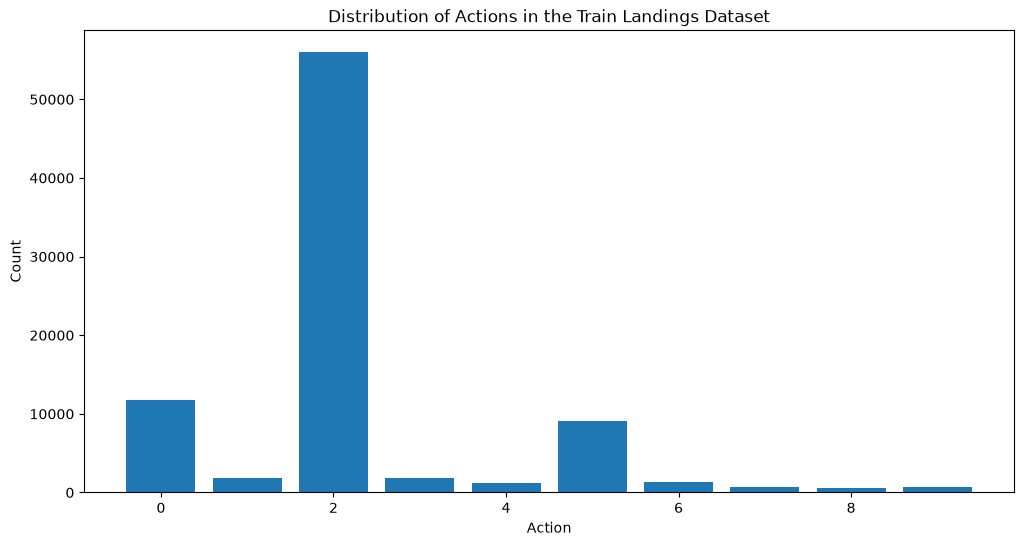

In [5]:
# -> Change 3: class weights, action 2 is ~66 % of the data so rare actions get ignored.
plt.figure(figsize=(12, 6))
plt.bar(train_landings["action"].value_counts().index, train_landings["action"].value_counts().values)
plt.title("Distribution of Actions in the Train Landings Dataset")
plt.xlabel("Action")
plt.ylabel("Count")
plt.show()

# This plot shows that action 2 is by far the most common. This might cause the classifier to be biased towards predicting action 2. 
# We might need to consider techniques like class weighting or oversampling to address this imbalance.



In [6]:
action_ratios = 1/ train_landings["action"].value_counts(normalize=True)
action_ratios

action
2      1.521641
0      7.222053
5      9.339476
1     45.877155
3     46.351660
6     63.260030
4     69.169781
7    120.095910
9    123.941776
8    138.003241
Name: proportion, dtype: float64

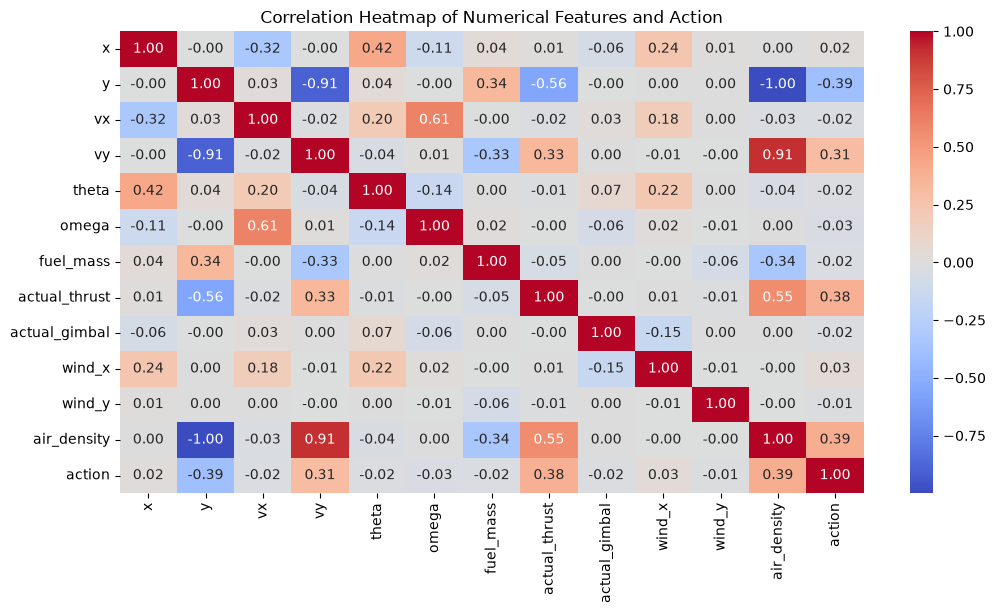

In [7]:
plt.figure(figsize=(12, 6))
y = "action"
sns.heatmap(train_landings[numerical_features + [y]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features and Action")
plt.show()

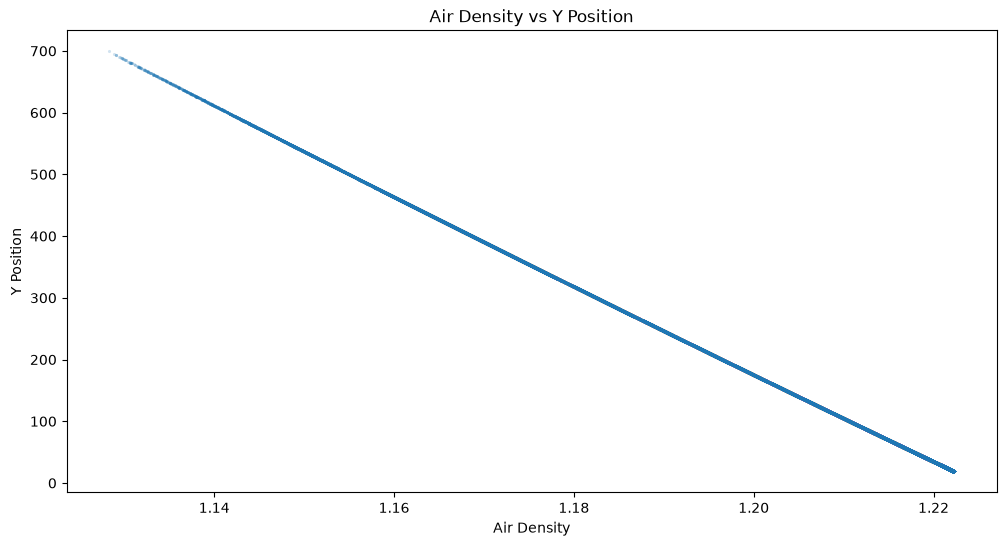

In [8]:
# -> Change 1: drop air_density, it's just y again (corr -1.00).
plt.figure(figsize=(12, 6))
sns.scatterplot(data=train_landings, x="air_density", y="y", s=5, alpha=0.2, linewidth=0)
plt.title("Air Density vs Y Position")
plt.xlabel("Air Density")
plt.ylabel("Y Position")
plt.show()
## Shows full linear correlation between air_density and y position (correlation -1.00) which is why we drop air_density as a feature in the model

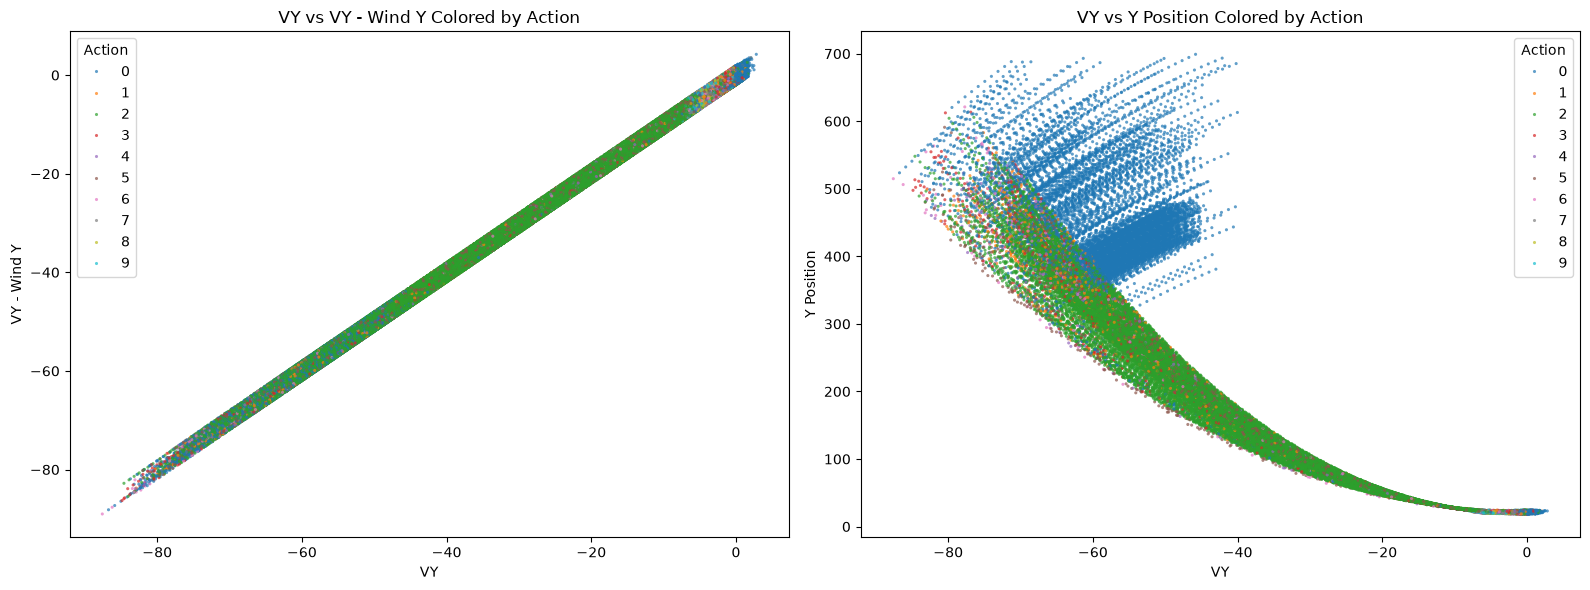

In [9]:
# -> Change 1: replace vy with vy - wind_y (speed relative to the air).
vy_rel = train_landings["vy"] - train_landings["wind_y"]  # vertical velocity relative to the air

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=train_landings["vy"], y=vy_rel, hue=train_landings["action"], palette="tab10", s=5, alpha=0.7, linewidth=0, ax=axes[0])
axes[0].set_title("VY vs VY - Wind Y Colored by Action")
axes[0].set_xlabel("VY")
axes[0].set_ylabel("VY - Wind Y")
axes[0].legend(title="Action")

sns.scatterplot(data=train_landings, x="vy", y="y", hue="action", palette="tab10", s=5, alpha=0.7, linewidth=0, ax=axes[1])
axes[1].set_title("VY vs Y Position Colored by Action")
axes[1].set_xlabel("VY")
axes[1].set_ylabel("Y Position")
axes[1].legend(title="Action")

plt.tight_layout()
plt.show()

# PLT1 shows that dropping wind_y and using vy-wind_y instead of vy is a good idea as it reduces the correlation between the features and makes the model more robust to changes in wind conditions. 
# PLT2 shows that there is a strong correlation between vy and y position, which is expected as the vertical velocity affects the vertical position of the lander.

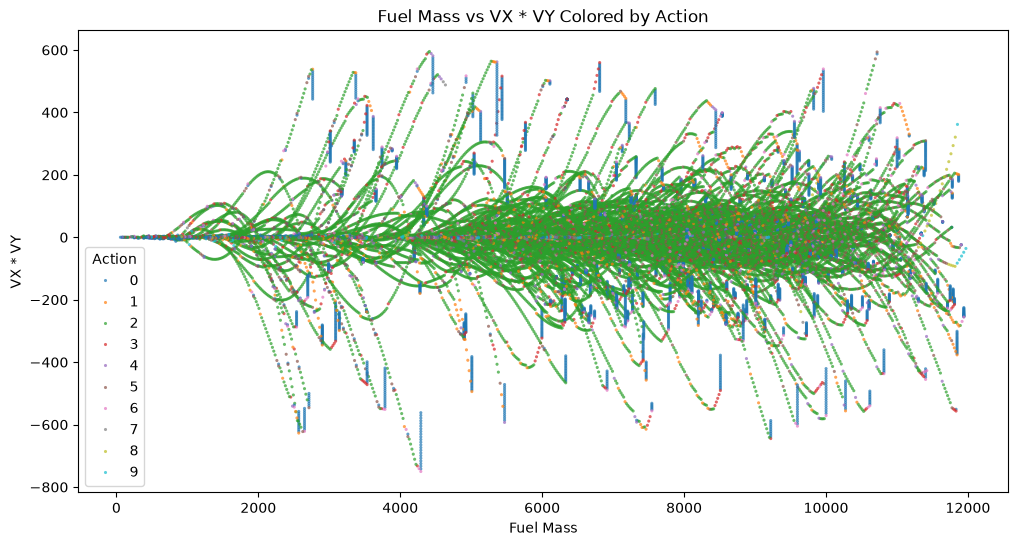

Correlation vx*vy vs fuel_mass: -0.013, vs action: 0.019


In [10]:
# -> No change: no pattern here, but it led to the braking idea (Change 4).
# Why: mass slows down how fast the velocity changes (a = F / m). If vx * vy shows a pattern against fuel_mass,
# a mass-scaled velocity feature might help.
vx_vy = train_landings["vx"] * train_landings["vy"]

plt.figure(figsize=(12, 6))
sns.scatterplot(x=train_landings["fuel_mass"], y=vx_vy, hue=train_landings["action"], palette="tab10", s=5, alpha=0.7, linewidth=0)
plt.title("Fuel Mass vs VX * VY Colored by Action")
plt.xlabel("Fuel Mass")
plt.ylabel("VX * VY")
plt.legend(title="Action")
plt.show()
print(f"Correlation vx*vy vs fuel_mass: {vx_vy.corr(train_landings['fuel_mass']):.3f}, vs action: {vx_vy.corr(train_landings['action']):.3f}")

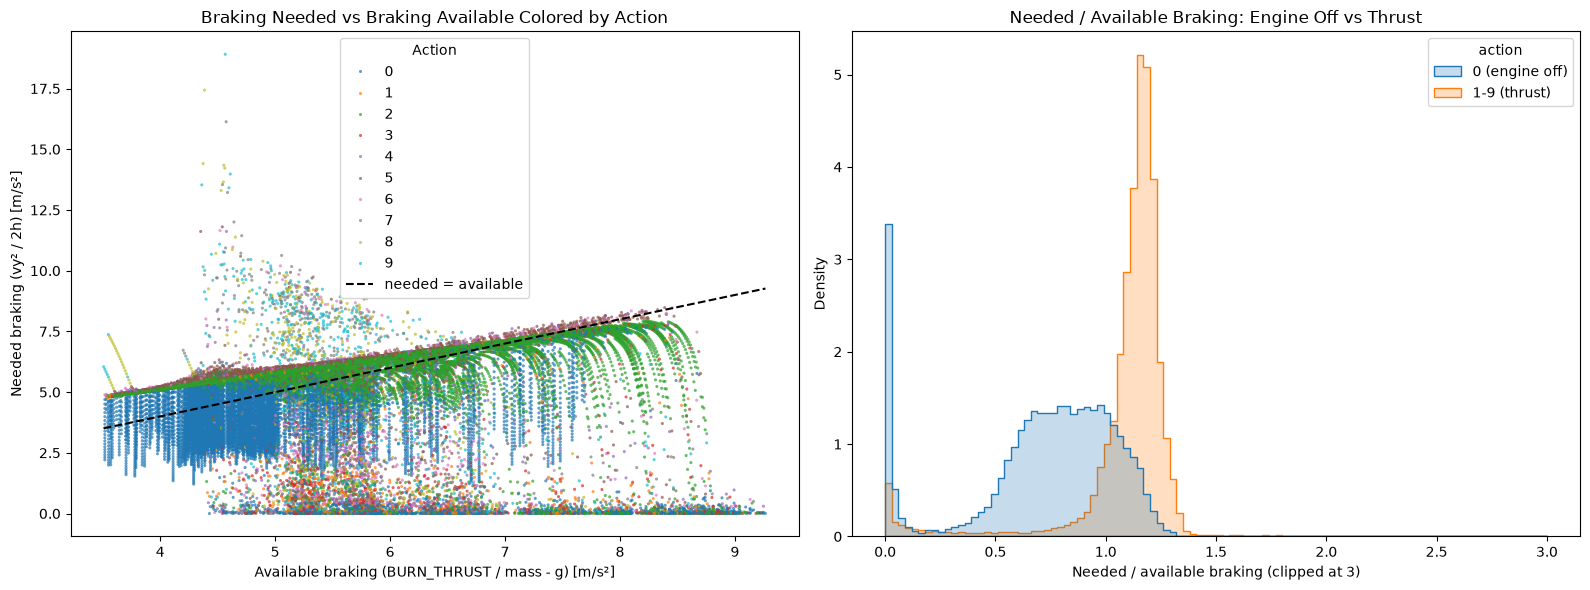

Median ratio when engine off: 0.79, when thrusting: 1.15


In [11]:
# -> Change 4: braking features (needed, available, ratio).
# Why: mass divides force, not velocity (a = F / m). So the real question is: can the engine still stop the rocket in time?
# Needed braking = vy² / 2h, available = thrust / mass - g. If the expert fires when they're about equal, the ratio
# is a strong feature for "thrust or not".
# DRY_MASS isn't in physics.pdf. From the burns: total mass = thrust / (vertical acceleration + g), minus fuel ≈ 27500 kg.
DRY_MASS = 27500
G = 9.80665
BURN_THRUST = 525560  # the expert's usual burn (levels: 0, 525560, 681650, 845000)
Y_GROUND = landings["y"].min()  # y never hits 0, lowest y = ground

total_mass = DRY_MASS + train_landings["fuel_mass"]
brake_available = BURN_THRUST / total_mass - G
brake_needed = train_landings["vy"] ** 2 / (2 * (train_landings["y"] - Y_GROUND + 1e-3))
brake_ratio = brake_needed / brake_available
engine = train_landings["action"].map(lambda a: "0 (engine off)" if a == 0 else "1-9 (thrust)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=brake_available, y=brake_needed.clip(upper=3 * brake_available.max()), hue=train_landings["action"], palette="tab10", s=5, alpha=0.7, linewidth=0, ax=axes[0])
line = [brake_available.min(), brake_available.max()]
axes[0].plot(line, line, "k--", label="needed = available")
axes[0].set_title("Braking Needed vs Braking Available Colored by Action")
axes[0].set_xlabel("Available braking (BURN_THRUST / mass - g) [m/s²]")
axes[0].set_ylabel("Needed braking (vy² / 2h) [m/s²]")
axes[0].legend(title="Action")

sns.histplot(x=brake_ratio.clip(upper=3), hue=engine, bins=100, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Needed / Available Braking: Engine Off vs Thrust")
axes[1].set_xlabel("Needed / available braking (clipped at 3)")

plt.tight_layout()
plt.show()
print(f"Median ratio when engine off: {brake_ratio[engine.str.startswith('0')].median():.2f}, when thrusting: {brake_ratio[~engine.str.startswith('0')].median():.2f}")

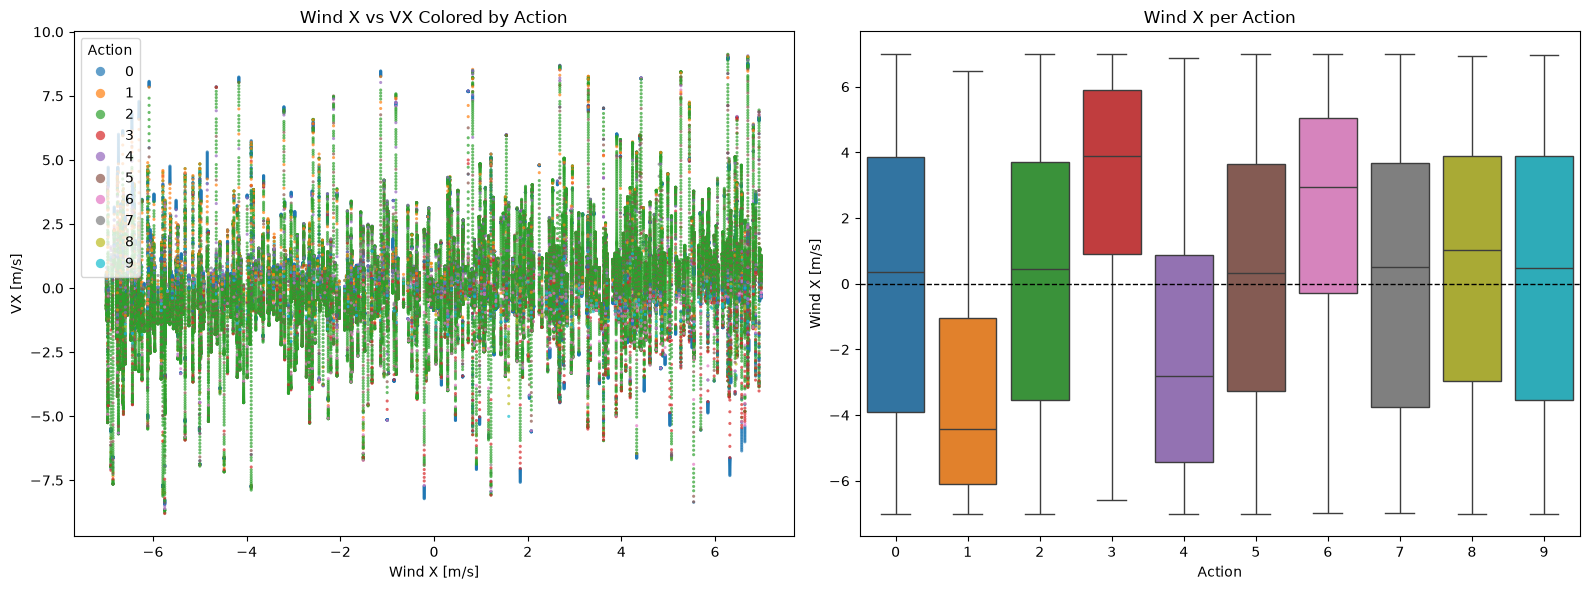

Correlation vx vs wind_x: 0.178


action,0,1,2,3,4,5,6,7,8,9
wind_x,0.02,-3.05,0.10,2.79,-2.03,0.09,2.15,0.10,0.45,0.16
vx,0.16,0.54,0.04,-0.26,0.39,0.04,-0.25,0.16,-0.04,-0.15


In [12]:
# -> No change of its own: the idea was wind_x × engine on (or × height). Change 5 covers the engine part.
# Why: drag depends on the speed relative to the air (v - v_wind). Change 1 used that vertically, this checks sideways:
# does wind_x push vx, and does the expert's action depend on it?
# Right: wind_x per action. wind_x is constant per landing, so the scatter is just vertical stripes.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=train_landings, x="wind_x", y="vx", hue="action", palette="tab10", s=5, alpha=0.7, linewidth=0, ax=axes[0])
axes[0].set_title("Wind X vs VX Colored by Action")
axes[0].set_xlabel("Wind X [m/s]")
axes[0].set_ylabel("VX [m/s]")
axes[0].legend(title="Action", loc="upper left", markerscale=3)

sns.boxplot(data=train_landings, x="action", y="wind_x", hue="action", palette="tab10", legend=False, showfliers=False, ax=axes[1])
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set_title("Wind X per Action")
axes[1].set_xlabel("Action")
axes[1].set_ylabel("Wind X [m/s]")

plt.tight_layout()
plt.show()
print(f"Correlation vx vs wind_x: {train_landings['vx'].corr(train_landings['wind_x']):.3f}")
display(train_landings.groupby("action")[["wind_x", "vx"]].mean().round(2).T)

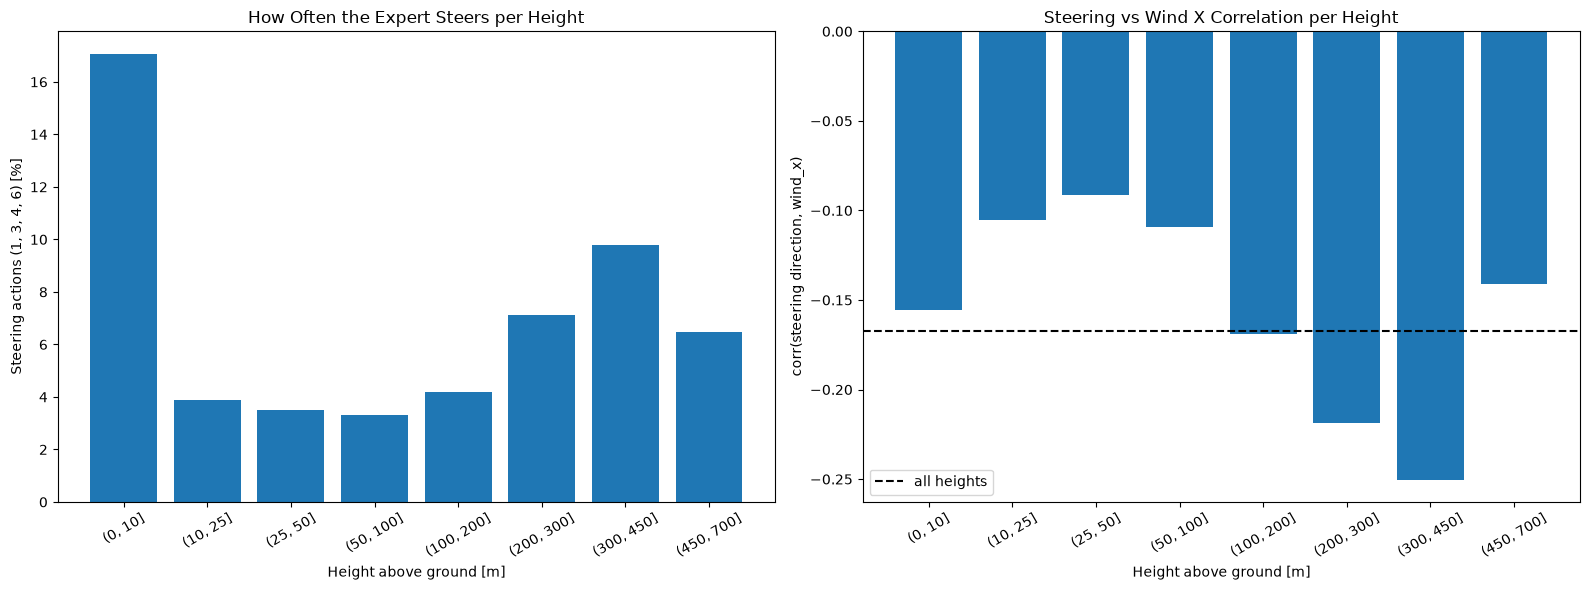

In [13]:
# -> Change 6: θ × exp(-height / 10 m), the steering burst below 10 m. (Kind of laying more emphasis on steering when close to the ground.)
#    Tested, not kept: wind_x × height (F1 0.3040 vs 0.3044), ω × exp(-height / 10 m) (F1 0.3053).
# Why: the box plot showed the expert steers against the wind (1/4 vs 3/6), but not WHEN. If steering depends on
# height, wind_x × height could tell the model when to steer.
# Left: how often the expert steers per height band. Right: how strongly the steering follows the wind there.
steer_direction = train_landings["action"].map({1: 1, 4: 1, 3: -1, 6: -1}).fillna(0)  # 1/4 one way, 3/6 the other
height_band = pd.cut(train_landings["y"] - train_landings["y"].min(), [0, 10, 25, 50, 100, 200, 300, 450, 700])
by_band = pd.DataFrame({"steer": steer_direction, "wind_x": train_landings["wind_x"], "band": height_band}).groupby("band", observed=True)
steer_rate = by_band["steer"].apply(lambda s: (s != 0).mean() * 100)
steer_wind_corr = by_band.apply(lambda g: g["steer"].corr(g["wind_x"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(steer_rate.index.astype(str), steer_rate.values)
axes[0].set_title("How Often the Expert Steers per Height")
axes[0].set_xlabel("Height above ground [m]")
axes[0].set_ylabel("Steering actions (1, 3, 4, 6) [%]")
axes[1].bar(steer_wind_corr.index.astype(str), steer_wind_corr.values)
axes[1].axhline(steer_direction.corr(train_landings["wind_x"]), color="k", linestyle="--", label="all heights")
axes[1].set_title("Steering vs Wind X Correlation per Height")
axes[1].set_xlabel("Height above ground [m]")
axes[1].set_ylabel("corr(steering direction, wind_x)")
axes[1].legend()
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

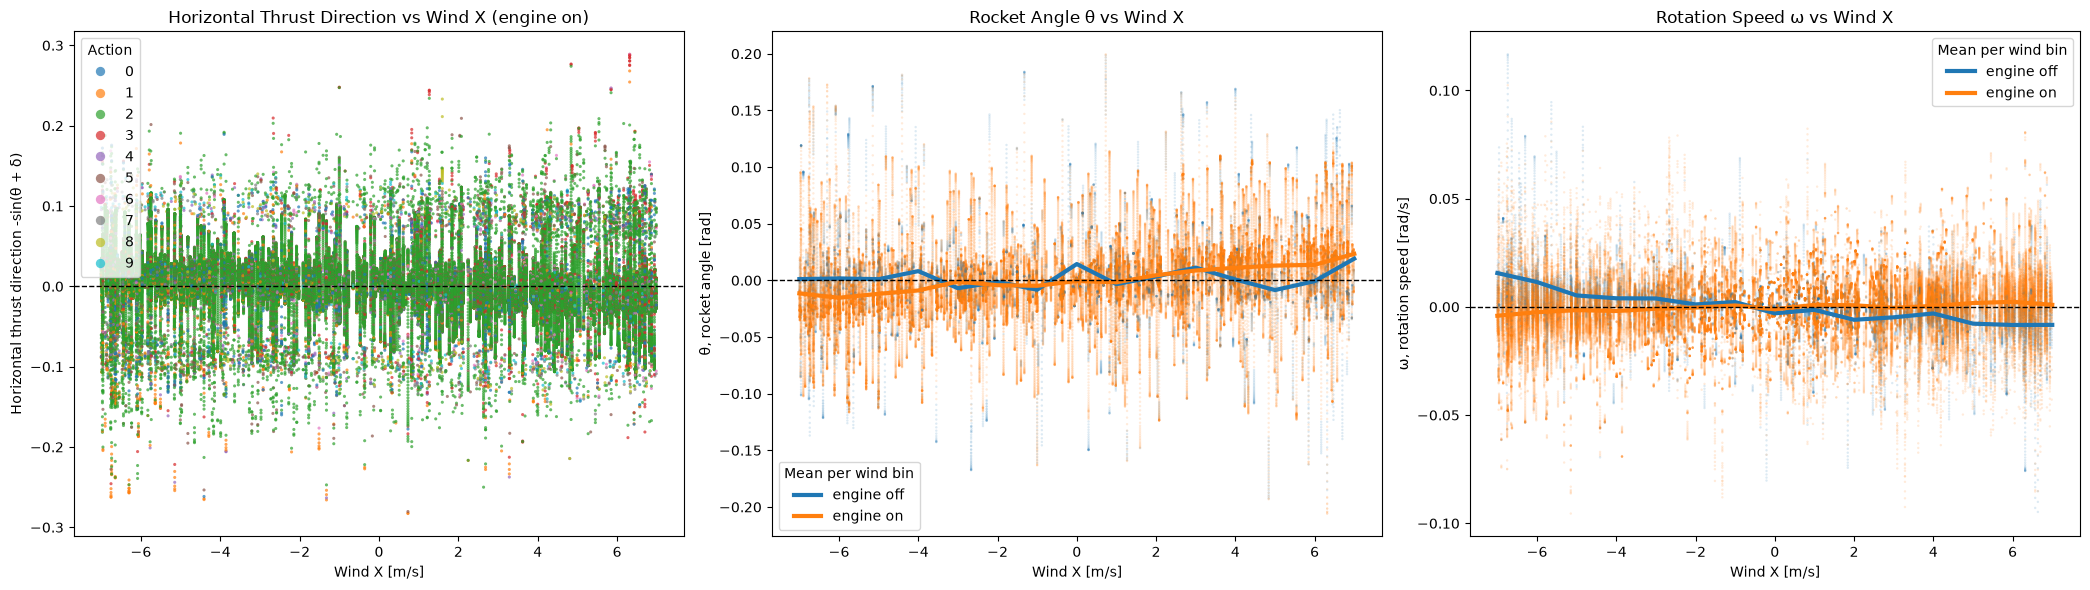

Correlation horizontal thrust direction vs wind_x (engine on): -0.113
engine off (12239 rows): corr θ vs wind_x = +0.017, corr ω vs wind_x = -0.374, median height = 426 m
engine on  (72909 rows): corr θ vs wind_x = +0.268, corr ω vs wind_x = +0.093, median height = 119 m


In [14]:
# -> Change 5: wind_x × engine off.
# Why: the sideways part of the thrust is -sin(θ + δ) (physics.pdf 0.2). If the expert fights the wind, it should lean
# against wind_x. Engine-on rows only, without thrust the direction doesn't matter.
# Middle/right: maybe the expert sometimes doesn't thrust and lets the wind turn the rocket. Then ω should follow the wind
# with the engine off. Lines = mean per 1 m/s of wind. ω only follows the wind with the engine off.
engine_on = train_landings[train_landings["actual_thrust"] > 0]
thrust_dir_x = -np.sin(engine_on["theta"] + engine_on["actual_gimbal"])
engine_state = np.where(train_landings["actual_thrust"] > 0, "engine on", "engine off")
wind_bins = train_landings["wind_x"].round()

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

sns.scatterplot(x=engine_on["wind_x"], y=thrust_dir_x, hue=engine_on["action"], palette="tab10", s=5, alpha=0.7, linewidth=0, ax=axes[0])
axes[0].axhline(0, color="k", linestyle="--", linewidth=1)
axes[0].set_title("Horizontal Thrust Direction vs Wind X (engine on)")
axes[0].set_xlabel("Wind X [m/s]")
axes[0].set_ylabel("Horizontal thrust direction -sin(θ + δ)")
axes[0].legend(title="Action", loc="upper left", markerscale=3)

for ax, column, label in [(axes[1], "theta", "θ, rocket angle [rad]"), (axes[2], "omega", "ω, rotation speed [rad/s]")]:
    sns.scatterplot(x=train_landings["wind_x"], y=train_landings[column], hue=engine_state, hue_order=["engine off", "engine on"],
                    s=3, alpha=0.15, linewidth=0, ax=ax, legend=False)
    sns.lineplot(x=wind_bins, y=train_landings[column], hue=engine_state, hue_order=["engine off", "engine on"],
                 errorbar=None, linewidth=3, ax=ax)
    ax.axhline(0, color="k", linestyle="--", linewidth=1)
    ax.set_xlabel("Wind X [m/s]")
    ax.set_ylabel(label)
    ax.legend(title="Mean per wind bin")
axes[1].set_title("Rocket Angle θ vs Wind X")
axes[2].set_title("Rotation Speed ω vs Wind X")

plt.tight_layout()
plt.show()
print(f"Correlation horizontal thrust direction vs wind_x (engine on): {thrust_dir_x.corr(engine_on['wind_x']):.3f}")
for state in ["engine off", "engine on"]:
    rows = train_landings[engine_state == state]
    print(f"{state:10s} ({len(rows):5d} rows): corr θ vs wind_x = {rows['theta'].corr(rows['wind_x']):+.3f}, "
          f"corr ω vs wind_x = {rows['omega'].corr(rows['wind_x']):+.3f}, median height = {rows['y'].median():.0f} m")

In [15]:
# Some metrics that may be useful for evaluating the model's performance.
def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()

def macro_f1_score(y_true, y_pred):
    try:
        from sklearn.metrics import f1_score
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    return f1_score(y_true, y_pred, average='macro')

def macro_precision_score(y_true, y_pred):
    try:
        from sklearn.metrics import precision_score
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    # zero_division=0: actions that are never predicted count as 0 instead of a warning
    return precision_score(y_true, y_pred, average='macro', zero_division=0)

def macro_recall_score(y_true, y_pred):
    try:
        from sklearn.metrics import recall_score
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    return recall_score(y_true, y_pred, average='macro', zero_division=0)

def confusion_matrix(y_true, y_pred):
    try:
        from sklearn.metrics import confusion_matrix
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    return confusion_matrix(y_true, y_pred)

In [32]:
action_boost = {8: 1.4, 5: 1.5, 1: 1.1, 3: 1.1}  # Change 7: extra weight for single actions (Model did not break enough). This did good theoretically but the rockets stopped landing and boosted until they ran out of fuel, so it needs to be adjusted
urgency_strength = 1.5  # Change 8: weight urgent moments (fast and close to the ground) more, harder braking actions more. 0 = off. (This fixed the rockets boosting until they ran out of fuel)
controller = Controller(learning_rate=learning_rate, epochs=epochs, class_weight_power=class_weight_power, action_boost=action_boost,
                        urgency_strength=urgency_strength)
train_X, train_y = train_landings[numerical_features], train_landings["action"]
val_X, val_y = val_landings[numerical_features], val_landings["action"]
controller = controller.fit(train_X, train_y, val_X, val_y)


### Model comparison (validation set)

Precision, recall and F1 are **macro** averages, so every action counts the same, rare ones included.
Accuracy alone is misleading: always guessing action 2 already gives ~66 %.

All models trained with learning rate 0.5 and 1000 epochs. unless specified otherwhise

With class weights (power > 0) the train loss is weighted, so compare rows by val loss. Val loss is always unweighted.

| Model | Split | Train loss | Val loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|
| Baseline (input model) | row | 0.7767 | 0.7849 | 0.7644 | 0.2447 | 0.2014 | 0.1991 |
| Change 1: drop air_density + wind_y, vy → vy − wind_y | row | 0.7812 | 0.7897 | 0.7649 | 0.2462 | 0.2009 | 0.1990 |
| Change 2: split by run_id | run_id | 0.7770 | 0.7871 | 0.7692 | 0.2638 | 0.2005 | 0.1970 |
| Change 2 + only successful runs in training | run_id | 0.7634 | 0.7866 | 0.7691 | 0.2670 | 0.1971 | 0.1915 |
| Change 3: class weights, power 0.5 (√ balanced) + only successful | run_id | 1.2968 | 0.9628 | 0.7373 | 0.2733 | 0.2858 | 0.2675 |
| Change 3: class weights, power 1 (balanced) + only successful | run_id | 1.5613 | 1.5996 | 0.3898 | 0.2535 | 0.4170 | 0.2489 |
| Change 4: braking features, no class weights + only successful | run_id | 0.7523 | 0.7754 | 0.7753 | 0.3110 | 0.2091 | 0.2068 |
| Change 4: braking features + class weights power 0.5 + only successful | run_id | 1.2623 | 0.9462 | 0.7459 | 0.3275 | 0.3154 | 0.2982 |
| Change 4 + power 0.5, normalisation fixed (mean/std from training only) | run_id | 1.2623 | 0.9705 | 0.7354 | 0.3131 | 0.3233 | 0.2975 |
| Change 5: wind_x × engine off + Change 4 + power 0.5 | run_id | 1.2562 | 0.9701 | 0.7346 | 0.3241 | 0.3337 | 0.3044 |
| Tested, not kept: Change 5 + wind_x × height | run_id | 1.2540 | 0.9703 | 0.7337 | 0.3229 | 0.3353 | 0.3040 |
| Tested, not kept: Change 5 + ω × exp(-height / 10 m) | run_id | 1.2533 | 0.9691 | 0.7340 | 0.3183 | 0.3384 | 0.3053 |
| Change 6: θ × exp(-height / 10 m) + Changes 1-5 + power 0.5 | run_id | 1.2510 | 0.9686 | 0.7365 | 0.3362 | 0.3420 | 0.3079 |
| Change 6, learning rate 1, 2000 epochs (after cross-validation) | run_id | 1.2196 | 0.9646 | 0.7278 | 0.3266 | 0.3552 | 0.3089 |
| Change 7: action 8 × 1.5 + Change 6, lr 1, 2000 epochs | run_id | 1.2310 | 0.9726 | 0.7228 | 0.3307 | 0.3538 | 0.3066 |
| Change 7: actions 5 and 8 × 1.5 + Change 6, lr 1, 2000 epochs | run_id | 1.2451 | 1.0083 | 0.6949 | 0.3171 | 0.3610 | 0.3235 |
| Change 8: urgency 1, no action boost + Change 6 | run_id | 1.2380 | 1.0065 | 0.7162 | 0.3166 | 0.3675 | 0.3157 |
| Change 8: urgency 1 + actions 5 and 8 × 1.5 + Change 6 | run_id | 1.2544 | 1.0578 | 0.6602 | 0.3142 | 0.3779 | 0.3295 |
| Change 8: urgency 1.2 + actions 5 and 8 × 1.5 + Change 6 | run_id | 1.2543 | 1.0649 | 0.6560 | 0.3130 | 0.3792 | 0.3290 |
| Final: urgency 1.5 + action 5 × 1.5, 8 × 1.4, 1 and 3 × 1.1 + Change 6 (tuned on the landing simulation) | run_id | 1.2572 | 1.0797 | 0.6486 | 0.3099 | 0.3780 | 0.3269 |
| Change 8: urgency 2 + actions 5 and 8 × 1.5 + Change 6 | run_id | 1.2525 | 1.0886 | 0.6422 | 0.3099 | 0.3782 | 0.3257 |

How often each action is predicted on the validation set (13015 rows):

| Action | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| True (expert) | 1707 | 300 | 8635 | 289 | 224 | 1399 | 204 | 91 | 75 | 91 |
| No weights (power 0) | 1805 | 20 | 11104 | 56 | 7 | 21 | 2 | 0 | 0 | 0 |
| Power 0.5 | 1737 | 301 | 9922 | 349 | 71 | 45 | 107 | 135 | 169 | 179 |
| Power 1 | 1444 | 1084 | 3169 | 998 | 626 | 3041 | 625 | 454 | 800 | 774 |
| Change 4, no weights | 1882 | 55 | 10938 | 78 | 3 | 55 | 4 | 0 | 0 | 0 |
| Change 4, power 0.5 | 1811 | 375 | 9931 | 367 | 56 | 19 | 96 | 98 | 122 | 140 |
| Change 4, power 0.5, normalisation fixed | 1730 | 374 | 9781 | 442 | 142 | 26 | 118 | 129 | 124 | 149 |
| Change 5, power 0.5 | 1735 | 416 | 9745 | 463 | 126 | 23 | 106 | 126 | 123 | 152 |
| Change 6, power 0.5 | 1746 | 408 | 9723 | 464 | 120 | 18 | 112 | 154 | 83 | 187 |
| Change 6, lr 1, 2000 epochs | 1708 | 395 | 9553 | 500 | 164 | 40 | 135 | 170 | 128 | 222 |
| Change 7, action 8 × 1.5 | 1690 | 387 | 9460 | 502 | 161 | 37 | 136 | 105 | 380 | 157 |
| Change 7, actions 5 and 8 × 1.5 | 1680 | 391 | 8571 | 508 | 163 | 972 | 128 | 96 | 356 | 150 |
| Change 8, urgency 1, no boost | 1569 | 378 | 9275 | 500 | 254 | 191 | 237 | 195 | 138 | 278 |
| Change 8, urgency 1 + 5 and 8 × 1.5 | 1526 | 377 | 7828 | 499 | 249 | 1627 | 226 | 107 | 372 | 204 |
| Change 8, urgency 1.2 + 5 and 8 × 1.5 | 1510 | 376 | 7742 | 498 | 260 | 1693 | 243 | 112 | 368 | 213 |
| Final | 1481 | 428 | 7594 | 542 | 258 | 1802 | 238 | 120 | 327 | 225 |
| Change 8, urgency 2 + 5 and 8 × 1.5 | 1447 | 378 | 7513 | 476 | 288 | 1909 | 290 | 115 | 366 | 233 |

Medium or full thrust (actions 4-9) on the validation set: expert 16.0 %, Change 6 6.6 %, action 8 × 1.5 7.5 %, actions 5 and 8 × 1.5 14.3 %, urgency 1 only 9.9 %, urgency 1 + 5 and 8 × 1.5 21.4 %, urgency 1.2 + 5 and 8 × 1.5 22.2 %, final 22.8 %, urgency 2 + 5 and 8 × 1.5 24.6 %.

In [17]:
# Prints a table row for the model trained above.
model_name = "Change X: describe the change"  # set before running
split_name = "run_id"

val_pred = controller.predict(val_X)
print(f"| {model_name} | {split_name} "
      f"| {controller.train_loss_history[-1]:.4f} | {controller.validation_loss_history[-1]:.4f} "
      f"| {accuracy(val_y, val_pred):.4f} | {macro_precision_score(val_y, val_pred):.4f} "
      f"| {macro_recall_score(val_y, val_pred):.4f} | {macro_f1_score(val_y, val_pred):.4f} |")

| Change X: describe the change | run_id | 1.2196 | 0.9646 | 0.7278 | 0.3266 | 0.3552 | 0.3089 |


In [33]:
controller.save(weights_path)
print(f"Model weights saved to {weights_path}")

Model weights saved to weights.npz


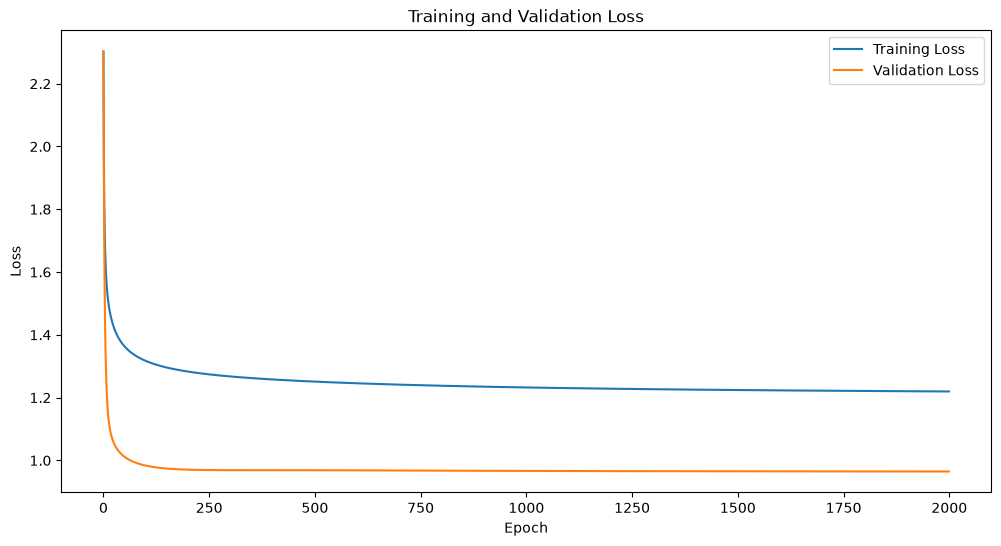

In [19]:
plt.figure(figsize=(12, 6))
plt.plot(controller.train_loss_history, label='Training Loss')
plt.plot(controller.validation_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Cross-validation: learning rate, epochs, L2

Model = Change 6 with the class weights and `only_successful_runs` from the settings cell.

In [20]:
# Why: one validation split can be lucky or unlucky. The 900 train + validation runs are split into 3 folds by run,
# each fold is held out once, the test runs stay untouched. Epochs come from weight snapshots, so every
# (learning rate, L2) pair is trained once per fold and scored at all epoch counts. Takes ~25 min.
cv_learning_rates = [0.25, 0.5, 1.0]
cv_l2_lambdas = [0.0, 1e-4, 1e-3, 1e-2]
cv_epochs = [250, 500, 1000, 2000]
n_folds = 3

cv_runs = run_ids.iloc[:n_train + n_val].to_numpy()  # train + validation runs, test stays out
cv_results = []
for fold_number, held_out_runs in enumerate(np.array_split(cv_runs, n_folds)):
    fold_train = landings[landings["run_id"].isin(cv_runs) & ~landings["run_id"].isin(held_out_runs)]
    if only_successful_runs:
        fold_train = fold_train[fold_train["success"] == 1]
    fold_val = landings[landings["run_id"].isin(held_out_runs)]  # held-out fold keeps all runs, like the validation set
    for lr in cv_learning_rates:
        for l2 in cv_l2_lambdas:
            model = Controller(learning_rate=lr, epochs=max(cv_epochs), class_weight_power=class_weight_power, l2_lambda=l2,
                               action_boost=action_boost, urgency_strength=urgency_strength)
            model.fit(fold_train[numerical_features], fold_train["action"], snapshot_epochs=cv_epochs)
            val_targets = (fold_val["action"].to_numpy()[:, None] == model.classes_).astype(float)
            for n_epochs, snapshot in model.weight_snapshots.items():
                model.weights = snapshot
                proba = model.predict_proba(fold_val[numerical_features])
                pred = model.classes_[np.argmax(proba, axis=1)]
                cv_results.append({"fold": fold_number, "learning_rate": lr, "l2_lambda": l2, "epochs": n_epochs,
                                   "val_loss": model.cross_entropy_loss(val_targets, proba),
                                   "f1": macro_f1_score(fold_val["action"], pred)})
            print(f"fold {fold_number + 1}/{n_folds}, lr {lr}, l2 {l2} done" + " " * 60)

cv_results = pd.DataFrame(cv_results)
cv_summary = (cv_results.groupby(["learning_rate", "l2_lambda", "epochs"])[["f1", "val_loss"]]
              .agg(["mean", "std"]).sort_values(("f1", "mean"), ascending=False))
display(cv_summary.head(10).round(4))

fold 1/3, lr 0.25, l2 0.0 done                                                            
fold 1/3, lr 0.25, l2 0.0001 done                                                            
fold 1/3, lr 0.25, l2 0.001 done                                                            


KeyboardInterrupt: 

In [ ]:
# Why: F1 against epochs for each learning rate, one panel per L2 strength. Flat lines = more epochs don't help,
# falling lines with more L2 = the penalty is too strong. Error bars = spread over the 3 folds.
fig, axes = plt.subplots(1, len(cv_l2_lambdas), figsize=(20, 5), sharey=True)
for ax, l2 in zip(axes, cv_l2_lambdas):
    part = cv_results[cv_results["l2_lambda"] == l2].assign(lr=lambda df: df["learning_rate"].astype(str))
    sns.lineplot(data=part, x="epochs", y="f1", hue="lr", marker="o", errorbar="sd", ax=ax)
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(cv_epochs, labels=[str(e) for e in cv_epochs])
    ax.set_title(f"L2 = {l2}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Macro F1 (mean over folds)")
    ax.legend(title="Learning rate")
plt.tight_layout()
plt.show()

### Cross-validation results

3 folds, mean ± std of macro F1 over the held-out folds.

| Learning rate | L2 | Epochs | F1 | Val loss |
|---|---|---|---|---|
| 1.0 | 0 | 2000 | **0.3117 ± 0.0021** | 0.9597 |
| 1.0 | 0.0001 | 2000 | 0.3107 ± 0.0022 | 0.9578 |
| 0.5 | 0 | 2000 | 0.3098 ± 0.0019 | 0.9624 |
| 1.0 | 0 | 1000 | 0.3098 ± 0.0018 | 0.9624 |
| 0.5 | 0 | 1000 (setting so far) | 0.3038 ± 0.0027 | 0.9657 |
| 1.0 | 0.001 | 2000 | 0.3029 ± 0.0041 | 0.9533 |
| 1.0 | 0.01 | 2000 | 0.2608 ± 0.0058 | 0.9787 |

- **Learning rate × epochs is what matters:** 0.5 × 2000 and 1.0 × 1000 give the same result. F1 is still rising at the end, so 0.5 / 1000 stopped too early.
- **L2 doesn't help:** 0.0001 changes nothing, 0.001 lowers F1 and 0.01 is clearly too strong. With ~160 weights and 85k rows there is no overfitting to fight.
- **Best:** learning rate 1.0, 2000 epochs, no L2.

### Objective

I mainly optimised for **agreement with the expert** (objective 1), measured with macro F1 instead of accuracy so the rare steering actions count too. The reason is practical: the simulator is only available online, so every landing test is slow, while agreement can be checked offline in minutes after each change.

Some decisions were still made with **landing success** (objective 2) in mind, so the result is a trade-off between the two:

- **Only successful runs in training:** the model copies the expert only where the expert actually landed.
- **Class weights:** lower accuracy (77 % → 74 %), but rare corrections like steering get learned instead of always predicting action 2.
- **Braking features and the near-ground θ boost:** aimed at the moments that decide a landing, timing the burn and staying upright at touchdown.
- **Normalisation fix:** without it the online controller would always pick the same action, no matter how good the offline scores are.

The consequence is that a better F1 does not guarantee more successful landings. Only the online evaluation can show that.

### Final settings

| Setting | Value |
|---|---|
| Learning rate / epochs | 1 / 2000 (from cross-validation) |
| Split | by run_id, 80 / 10 / 10 |
| Training data | only successful landings |
| Features | Changes 1, 4, 5, 6 + normalisation fix |
| Class weights (Change 3) | power 0.5 |
| Action boost (Change 7) | action 5 × 1.5, action 8 × 1.4, actions 1 and 3 × 1.1 |
| Urgency (Change 8) | 1.5 |
| L2 | 0 (didn't help in cross-validation) |

Validation: accuracy 0.649, macro F1 0.327, val loss 1.080.

Changes 7 and 8 came from trying to get a better landing score, not a better match with the expert. In the landing footage the rocket came down too fast, so I tuned the action boost and the urgency by hand using the online landing simulation. Boosting the braking actions alone made the rockets hover until they ran out of fuel, the urgency weighting fixed that. The last change was a small boost to low engine steering because sometimes the horizontal speed was a bit to high. Offline this costs agreement: compared to Change 6 with the same learning rate and epochs, accuracy dropped from 0.728 to 0.649 and val loss rose from 0.965 to 1.080. Macro F1 went up (0.309 → 0.327) because the rare braking actions are now predicted more often. 

### AI disclaimer

I used an AI coding assistant (Claude Code by Anthropic, inside VS Code) for this notebook and `scaffold.py`. This is how it went:

- **My part:** I looked at the plots, came up with the ideas and decided what to keep. I told the AI what to plot and which features to try: dropping air_density and using vy − wind_y, training only on successful landings, weighting rare actions, the wind turning the rocket while the engine is off (Change 5), and boosting θ near the ground (Change 6). I also picked learning rate 0.5 with 1000 epochs to save time and asked for the L2 / cross-validation run.
- **The AI's part:** it wrote most of the code, ran the training runs and filled in the table. It also helped shape some of the ideas along the way and pointed out a few problems in the code.
- **Checking:** every idea was trained and compared in the table, including the ones that didn't help (wind_x × height, ω near the ground, putting air_density back). The AI was wrong a few times, e.g. it expected ω to work better near the ground than θ, and the results showed the opposite. I went with what the numbers said.

# Remark

⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣀⣀⣤⣀⢠⡤⠤⠖⠒⠒⠒⠲⣆⠀⠀⠀⠀⣾⠋⠉⠉⠛⢷⠀⣴⠖⠒⠤⣄⠀⣀⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣀⣤⠤⠶⢺⣾⣏⠁⠀⠀⣧⣼⣇⣀⠀⠀⠀⡀⠀⠘⡆⠀⠀⢰⣏⠀⠀⠀⠀⠘⣿⡟⠀⠀⢠⢃⣼⡏⠉⠙⢳⡆⠀⠀⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⣀⡤⠴⠒⠋⠙⣇⣿⠀⠀⠀⣿⣿⠀⠀⠀⢸⣿⣿⣿⠃⠀⢰⣿⡀⠀⠹⡄⠀⢸⣿⠀⠀⠀⠀⠀⢹⡇⠀⠀⢸⡿⣽⠀⠀⠀⡜⠀⣀⡤⠖⠓⠢⢤⣀⠀\
⣠⡴⠒⠉⠁⠀⠀⠀⠀⠀⠸⣿⡇⠀⠀⠘⠛⠃⠀⠀⠈⡟⠉⣿⠀⠀⠘⠛⠃⠀⠀⢷⠀⢸⣿⠀⠀⢠⡀⠀⠀⠀⠀⠀⣿⢧⡇⠀⠀⠸⠗⠚⠁⠀⠀⠀⣀⣠⣾⠃\
⣿⡇⠀⠀⠀⠀⠀⠀⣶⣶⣿⢿⢹⠀⠀⠀⢀⣀⠀⠀⠀⢳⠀⣿⠀⠀⢀⣀⣤⠀⠀⠘⣇⢸⡏⠀⠀⢸⣧⠀⠀⠀⠀⢸⣿⡿⠀⠀⢀⠀⠀⠀⢀⣤⣶⣿⠿⠛⠁⠀\
⢧⣹⣶⣾⣿⡄⠀⠀⠸⡟⠋⠘⡜⡆⠀⠀⢻⣿⡇⠀⠀⢸⡀⣿⠀⠀⢸⣿⡿⡇⠀⠀⢸⣿⡇⠀⠀⢸⡿⡆⠀⠀⠀⣾⣿⠃⠀⠀⣾⡇⠀⠀⠈⡟⠉⠀⠀⠀⠀⠀\
⠘⣿⡿⠿⢿⣧⠀⠀⠀⢳⡀⠀⣇⢱⠀⠀⠈⣿⣷⠀⣀⣸⣷⣿⣤⣤⣼⠋⣇⣹⣶⣶⣾⣿⡿⢲⣶⣾⡇⣿⣤⣀⣀⣿⡏⠀⠀⣼⡏⢧⠀⠀⠀⣇⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠸⡞⣇⠀⠀⠀⢧⠀⢸⣈⣷⣶⣶⣿⣿⣿⣿⣿⣿⣿⣽⣿⡏⢀⡼⠟⠛⠻⢿⡿⠿⠿⣿⣁⣿⣿⣿⣿⣿⣿⣿⣶⣴⢿⠁⢸⠀⠀⠀⢸⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⢹⣼⣦⣤⣶⣿⠁⣀⣿⠿⠿⣿⣫⣿⠉⠁⠀⠀⠀⡏⠀⣴⠏⠀⠀⠀⠀⠀⠹⣆⠀⢠⣿⠀⠀⠀⢈⠟⢻⡿⠿⣅⣘⡆⣸⣇⠀⠀⢸⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠻⠿⠿⠛⠃⢠⣿⣷⣄⠀⠈⠙⠋⠀⠀⠀⠀⣸⢁⡾⠁⠀⠀⣠⣤⡀⠀⠀⠸⣤⡞⡇⠀⠀⠀⢸⣰⣿⠃⠀⠀⢹⣿⣿⣿⣿⣦⣼⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠻⢿⣿⣿⣷⣄⠀⠀⠀⠀⠀⠀⣿⣾⠇⠀⠀⣸⣿⣿⢿⠀⠀⠀⣿⢁⡇⠀⠀⢀⣿⣿⡏⠀⠀⠀⡼⠀⢙⣿⠛⠻⣏⡀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠙⢿⣿⣿⣷⠀⠀⠀⠀⢸⡿⡿⠀⠀⠀⡏⢹⠟⡟⠀⠀⠀⡿⢸⠀⠀⠀⢸⣿⡿⠀⠀⠀⢠⠇⡰⢋⡏⠀⠀⠀⢙⡆⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠙⡿⡿⠀⠀⠀⠀⣸⡇⡇⠀⠀⠀⠻⠾⠞⠁⠀⠀⢀⡇⡏⠀⠀⠀⢸⣿⠃⠀⠀⠀⡼⣰⠃⡞⠀⠀⠀⠀⡾⠁⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⡇⡇⠀⠀⠀⠀⣿⣇⣷⠀⠀⠀⠀⠀⠀⠀⠀⠀⣼⣃⡇⠀⠀⠀⠀⠀⠀⠀⠀⣼⣷⠃⣼⡀⠀⠀⢀⡞⠁⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢸⢸⠃⠀⠀⠀⢀⡇⢿⣿⣧⣀⠀⠀⠀⠀⠀⣠⣾⣿⣿⣧⠀⠀⠀⠀⠀⠀⠀⣸⣿⣿⣿⣽⣿⣷⣤⡞⠁⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣾⣼⣤⣶⣶⣶⡿⠁⠈⢿⣿⣿⣿⣿⣿⣿⣿⠿⠃⢸⣿⣿⣷⣤⣄⣀⣀⣤⣾⣏⣤⡟⠁⠀⠈⠻⡍⠀⠀⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣿⠿⠿⠿⠟⠛⠁⠀⠀⠀⠉⠛⠛⠛⠛⠉⠁⠀⠀⠀⠙⠿⢿⣿⣿⡿⠿⠋⢀⣿⣿⣧⡀⠀⠀⣠⡇⠀⠀⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢿⣿⣿⣿⣿⠟⠋⠀⠀⠀⠀⠀⠀⠀⠀⠀\
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠉⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀\
This task was a lot of fun :D